# Aqueous solubility (logS) regression with ensemble models

Exercise from the ITMO course *Artificial Intelligence in a Chemist's Work*.

**Data:** AqSolDB-derived table (`prepared_solubility.csv`, provided in the course) with 13 RDKit descriptors per molecule
(logP, molar refractivity, H-bond donors/acceptors, ring counts, TPSA, Labute ASA, Balaban J).
**Task:** improve on the linear-regression baseline from the class (MSE 2.04, R² 0.63) using ensemble models,
and tune hyperparameters with cross-validation.


In [77]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [78]:
# Data file from the course; place it in data/ before running
s_data = pd.read_csv('data/prepared_solubility.csv', nrows=10000)

In [79]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [80]:
s_data.head(3)

,Name,SMILES,Solubility,Group,MolLogP,MolMR,NumHAcceptors,NumHDonors,NumHeteroatoms,NumRotatableBonds,NumAromaticRings,NumSaturatedRings,NumAliphaticRings,RingCount,TPSA,LabuteASA,BalabanJ
0,"N,N,N-trimethyloctadecan-1-aminium bromide",[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,G1,3.9581,102.4454,0.0,0.0,2.0,17.0,0.0,0.0,0.0,0.0,0.00,158.520601,0.000000
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767,G1,2.4055,51.9012,1.0,1.0,2.0,0.0,2.0,0.0,1.0,3.0,29.10,75.183563,2.582996
2,4-chlorobenzaldehyde,Clc1ccc(C=O)cc1,-2.177078,G1,2.1525,36.8395,1.0,0.0,2.0,1.0,1.0,0.0,0.0,1.0,17.07,58.261134,3.009782


In [81]:
# All numeric columns except the target are used as features
X = s_data.select_dtypes(include=['float64', 'int64']).drop(columns=['Solubility'])
y = s_data['Solubility']

print('Number of features:', X.shape[1])
print(list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('\nTrain set:', X_train.shape, ' Test set:', X_test.shape)

Number of features: 13
['MolLogP', 'MolMR', 'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms', 'NumRotatableBonds', 'NumAromaticRings', 'NumSaturatedRings', 'NumAliphaticRings', 'RingCount', 'TPSA', 'LabuteASA', 'BalabanJ']

Train set: (7585, 13)  Test set: (1897, 13)


In [82]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [83]:
# Two ensemble models: gradient boosting, and stacking of random forest + gradient boosting
results = {}

models = {
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Stacking': StackingRegressor(estimators=[
                                             ('rf', RandomForestRegressor(random_state=42)),
                                             ('gb', GradientBoostingRegressor(random_state=42))
                                             ],
                                  final_estimator=LinearRegression()
                                 )
         }

for name, model in models.items():
    # Fit
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store results
    results[name] = {'mse': mse, 'r2': r2, 'y_pred': y_pred}

    # Report
    print(f"{name}:\nMSE: {mse}\nR2 Score: {r2}\n")

Gradient Boosting:
MSE: 1.3741397734917091
R2 Score: 0.7517537349893663

Stacking:
MSE: 1.2224549812432293
R2 Score: 0.7791564664006816



In [84]:
# Hyperparameter search for gradient boosting (5-fold CV)
from sklearn.model_selection import GridSearchCV, KFold

gb_grid = GradientBoostingRegressor(random_state=0)

# Parameter grid
param_grid = {
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': [3, 4, 5, 6, 8],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', 'log2'],
}

kfold = KFold(n_splits=5, shuffle=True, random_state=0)

grid_search = GridSearchCV(gb_grid, param_grid, cv=kfold, scoring='r2')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV R2:", grid_search.best_score_)

Best parameters: {'criterion': 'squared_error', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 10}
Best CV R2: 0.7716243471062726


In [85]:
# Tuned model on the held-out test set
gb_best = grid_search.best_estimator_
y_pred_grid = gb_best.predict(X_test)

In [87]:
mse_grid = mean_squared_error(y_test, y_pred_grid)
r2_grid = r2_score(y_test, y_pred_grid)

print("MSE, tuned gradient boosting:", mse_grid)
print("R2,  tuned gradient boosting:", r2_grid)

results['Gradient Boosting (tuned)'] = {'mse': mse_grid, 'r2': r2_grid, 'y_pred': y_pred_grid}

MSE, tuned gradient boosting: 1.216816321333643
R2,  tuned gradient boosting: 0.7801751227915545


In [88]:
# Stacking with the tuned booster inside
stack_tuned = StackingRegressor(
    estimators=[
        ('rf',  RandomForestRegressor(random_state=42)),
        ('gb',  gb_best),   # tuned booster
    ],
    final_estimator=LinearRegression()
)
stack_tuned.fit(X_train, y_train)
y_pred_stack = stack_tuned.predict(X_test)

mse_stack = mean_squared_error(y_test, y_pred_stack)
r2_stack = r2_score(y_test, y_pred_stack)
results['Stacking (tuned)'] = {'mse': mse_stack, 'r2': r2_stack, 'y_pred': y_pred_stack}

print(f"Stacking (tuned):\nMSE: {mse_stack}\nR2 Score: {r2_stack}")

Stacking (tuned):
MSE: 1.1934641726869872
R2 Score: 0.7843938229509823


In [91]:
# Linear-regression baseline from the class, for comparison
results['Linear regression (class baseline)'] = {'mse': 2.044, 'r2': 0.631, 'y_pred': None}

comparison = pd.DataFrame([{'Model': k, 'MSE': v['mse'], 'R2': v['r2']}
                           for k, v in results.items()]).sort_values('MSE')
comparison['MSE reduction vs baseline, %'] = ((2.044 - comparison['MSE']) / 2.044 * 100).round(1)
comparison

,Model,MSE,R2,"MSE reduction vs baseline, %"
3,Stacking (tuned),1.193464,0.784394,41.6
2,Gradient Boosting (tuned),1.216816,0.780175,40.5
1,Stacking,1.222455,0.779156,40.2
0,Gradient Boosting,1.374140,0.751754,32.8
4,Linear regression (class baseline),2.044000,0.631000,0.0


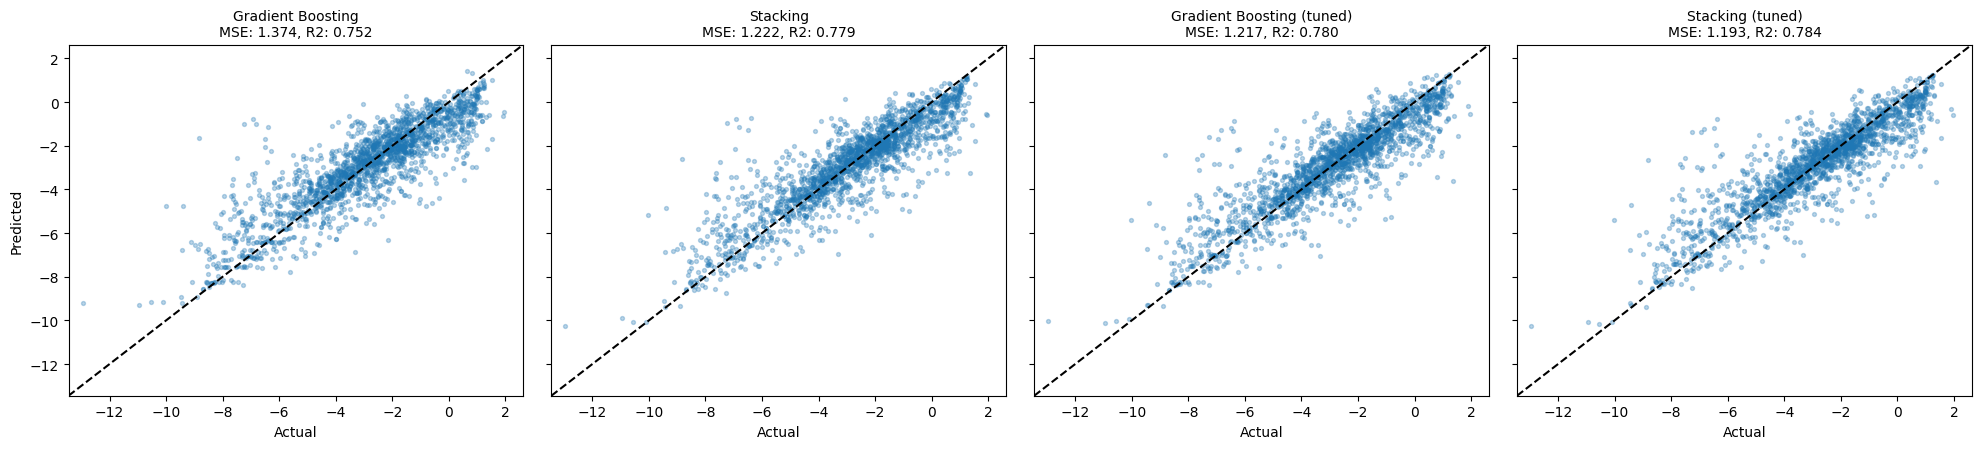

In [92]:
# Predicted vs. actual logS on the test set
plot_models = {k: v for k, v in results.items() if v['y_pred'] is not None}

fig, axes = plt.subplots(1, len(plot_models), figsize=(5 * len(plot_models), 4.6),
                         sharex=True, sharey=True)
lims = [y.min() - 0.5, y.max() + 0.5]

for ax, (name, result) in zip(axes, plot_models.items()):
    ax.scatter(y_test, result['y_pred'], alpha=0.3, s=8)
    ax.plot(lims, lims, 'k--', lw=1.5)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel('Actual')
    ax.set_title(f"{name}\nMSE: {result['mse']:.3f}, R2: {result['r2']:.3f}", fontsize=10)

axes[0].set_ylabel('Predicted')
plt.tight_layout()
plt.show()

## Conclusions

1. Two ensemble models were built: gradient boosting, and stacking of random forest + gradient boosting.
   The best result came from stacking with the tuned booster inside: MSE 1.193, R² 0.784.
2. Most of the gain comes from moving to non-linear models: gradient boosting with default parameters raised R² from 0.631 to 0.752 without any tuning.
   Solubility therefore depends non-linearly on these descriptors, with feature interactions a linear model cannot capture.
3. The remaining error reflects the small set of 13 descriptors and the experimental scatter of AqSolDB, which merges
   measurements made by different methods. Further improvement is more likely from a richer feature set than from more tuning.
